# MobileRec: Evaluation and Analysis of Results

This notebook reloads saved model checkpoints and extends the final evaluation without retraining. All six models are evaluated on the same test targets and the same set of 10,172 candidate apps. In addition to overall performance, the analysis examines user history length, target-app popularity and category, and catalog coverage.


## 1. Preparing Data and Models for Evaluation

Evaluation uses the original chronological split and the previously selected model checkpoints. Each test target is the user’s final recorded interaction, while every model uses only training interactions as input. This gives all models the same available user context.

Results are computed for K ∈ {1, 5, 10, 15, 20}. Since each user has exactly one target app, Hit@K and Recall@K are equivalent. NDCG@K additionally accounts for the target’s position in the recommendation list.


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import gc
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.sparse import coo_matrix, load_npz

In [2]:
run_name = "all_users"
seed = 42
k_values = [1, 5, 10, 15, 20]
max_k = max(k_values)

history_batch = 128
knn_batch = 250
neumf_batch = 64
lightgcn_batch = 1024
force_recompute = False

In [3]:
split_dir = Path("artifacts") / "split_all_users"
baseline_dir = Path("artifacts") / "baselines_all_users"
autoencoder_dir = Path("artifacts") / "autoencoders_all_users"
neumf_dir = Path("artifacts") / "neumf_all_users"
lightgcn_dir = Path("artifacts") / "lightgcn_all_users"
analysis_dir = Path("artifacts") / "extended_evaluation_all_users"
analysis_dir.mkdir(parents=True, exist_ok=True)

train_path = split_dir / "train_all_users.parquet"
valid_path = split_dir / "validation_all_users.parquet"
test_path = split_dir / "test_all_users.parquet"
user_map_path = split_dir / "users_map_all_users.parquet"
item_map_path = split_dir / "items_map_all_users.parquet"
popularity_path = split_dir / "apps_popularity_all_users.parquet"
metadata_path = Path("artifacts") / "final" / "metadata_final.parquet"
matrix_path = baseline_dir / f"user_item_matrix_{run_name}_seed_{seed}.npz"
knn_path = baseline_dir / f"item_neighbors_300_{run_name}_seed_{seed}.npz"
knn_tuning_path = baseline_dir / f"itemknn_tuning_{run_name}_seed_{seed}.csv"
saved_results_path = lightgcn_dir / f"all_results_{run_name}_seed_{seed}.csv"

model_paths = {
    "AutoRec": autoencoder_dir / f"ar_{run_name}_seed_{seed}.pt",
    "MultiVAE": autoencoder_dir / f"multivae_{run_name}_seed_{seed}.pt",
    "NeuMF": neumf_dir / f"neumf_{run_name}_seed_{seed}.pt",
    "LightGCN": lightgcn_dir / f"lightgcn_{run_name}_seed_{seed}.pt",
}

required_paths = [
    train_path, valid_path, test_path, user_map_path, item_map_path, popularity_path, metadata_path, matrix_path, knn_path, knn_tuning_path, 
    saved_results_path, *model_paths.values()
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"File does not exist: {path}")


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(seed)
torch.manual_seed(seed)
if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [5]:
user_map = pd.read_parquet(user_map_path).sort_values("user_idx").reset_index(drop=True)
item_map = pd.read_parquet(item_map_path).sort_values("item_idx").reset_index(drop=True)
app_counts = pd.read_parquet(popularity_path).sort_values(
    ["interaction_count", "item_idx"], ascending=[False, True]
).reset_index(drop=True)
metadata = pd.read_parquet(
    metadata_path, columns=["app_package", "app_name", "app_category"]
)
user_item_matrix = load_npz(matrix_path).tocsr()
num_users, num_items = user_item_matrix.shape

assert num_users == len(user_map)
assert num_items == len(item_map)

def load_targets(path):
    data = pd.read_parquet(path, columns=["uid", "app_package"])
    data = data.merge(user_map[["uid", "user_idx"]], on="uid", how="left")
    data = data.merge(item_map[["app_package", "item_idx"]], on="app_package", how="left")
    targets = data.dropna(subset=["item_idx"]).copy()
    targets["user_idx"] = targets["user_idx"].astype("int32")
    targets["item_idx"] = targets["item_idx"].astype("int32")
    return data, targets.sort_values("user_idx").reset_index(drop=True)

valid_data, valid_targets = load_targets(valid_path)
test_data, test_targets = load_targets(test_path)
test_coverage = len(test_targets) / len(test_data) * 100

print("Users:", num_users)
print("Kandidat applications:", num_items)
print("Test targets present in the candidate set:", len(test_targets))
print("Test-target coverage:", round(test_coverage, 6), "%")


Users: 700111
Kandidat applications: 10172
Test targets present in the candidate set: 700096
Test-target coverage: 99.997857 %


In [6]:
con = duckdb.connect()
history_size = con.execute(f"""
    SELECT uid, COUNT(*) AS test_history_size
    FROM read_parquet('{train_path.as_posix()}')
    GROUP BY uid
""").fetchdf()
con.close()

per_user_path = analysis_dir / f"per_user_metrics_{run_name}_seed_{seed}.parquet"
catalog_counts_path = analysis_dir / f"catalog_counts_{run_name}_seed_{seed}.parquet"

base_user = test_targets[["uid", "app_package", "user_idx", "item_idx"]].copy()
base_user = base_user.merge(history_size, on="uid", how="left", validate="one_to_one")
base_user = base_user.merge(
    metadata[["app_package", "app_category"]], on="app_package", how="left"
)
base_user = base_user.merge(
    app_counts[["item_idx", "interaction_count"]].rename(
        columns={"interaction_count": "target_train_interactions"}
    ),
    on="item_idx", how="left", validate="many_to_one"
)

base_user["history_group"] = pd.cut(
    base_user["test_history_size"],
    bins=[0, 8, 15, 30, np.inf],
    labels=["3–8", "9–15", "16–30", "31+"],
)

popularity_rank = app_counts[["item_idx"]].copy()
popularity_rank["popularity_rank"] = np.arange(1, len(popularity_rank) + 1)
popularity_rank["popularity_fraction"] = (
    (popularity_rank["popularity_rank"] - 1) / num_items
)
popularity_rank["target_popularity_group"] = pd.cut(
    popularity_rank["popularity_fraction"],
    bins=[-0.001, 0.10, 0.50, 1.0],
    labels=["Top 10% most popular", "Next 40%", "Bottom 50% least popular"],
    include_lowest=True,
)
base_user = base_user.merge(
    popularity_rank[["item_idx", "popularity_rank", "target_popularity_group"]],
    on="item_idx", how="left", validate="many_to_one"
)

if per_user_path.exists() and not force_recompute:
    per_user = pd.read_parquet(per_user_path)
    if not np.array_equal(per_user["user_idx"].to_numpy(), base_user["user_idx"].to_numpy()):
        raise ValueError("Saved results do not match the current test set.")
else:
    per_user = base_user.copy()

if catalog_counts_path.exists() and not force_recompute:
    catalog_counts = pd.read_parquet(catalog_counts_path)
else:
    catalog_counts = pd.DataFrame(columns=[
        "model", "item_idx", "recommendation_count_at_10", "recommendation_count_at_20"
    ])

print("Groups by history length:")
display(base_user["history_group"].value_counts(sort=False).to_frame("users"))
print("Groups by target-application popularity:")
display(base_user["target_popularity_group"].value_counts(sort=False).to_frame("test_targets"))


Groups by history length:


,users
history_group,
3–8,432406
9–15,61776
16–30,53425
31+,152489


Groups by target-application popularity:


,test_targets
target_popularity_group,
Top 10% most popular,289925
Next 40%,348135
Bottom 50% least popular,62036


### Saved Neural Model Architectures

Only the architectures required to load the saved weights are redefined below. Training functions are unnecessary because the models are not updated in this notebook.


In [7]:
class AutoRec(nn.Module):
    def __init__(self, num_items, latent, dropout):
        super().__init__()
        self.encoder = nn.Linear(num_items, latent)
        self.dropout = nn.Dropout(dropout)
        self.decoder = nn.Linear(latent, num_items)

    def forward(self, history):
        hidden = torch.relu(self.encoder(history))
        hidden = self.dropout(hidden)
        return self.decoder(hidden)


class MultiVAE(nn.Module):
    def __init__(self, num_items, hidden, latent, dropout):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.encoder = nn.Linear(num_items, hidden)
        self.mean_logvar = nn.Linear(hidden, latent * 2)
        self.decoder = nn.Linear(latent, hidden)
        self.output = nn.Linear(hidden, num_items)

    def forward(self, history, values=False):
        history = F.normalize(history, p=2, dim=1)
        hidden = torch.tanh(self.encoder(self.dropout(history)))
        mean, logvar = torch.chunk(self.mean_logvar(hidden), 2, dim=1)
        latent = mean if not self.training else mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)
        scores = self.output(torch.tanh(self.decoder(latent)))
        if values:
            return scores, mean, logvar
        return scores


class NeuMF(nn.Module):
    def __init__(self, num_users, num_items, dim, mlp_layers):
        super().__init__()
        self.gmf_user = nn.Embedding(num_users, dim)
        self.gmf_app = nn.Embedding(num_items, dim)
        self.mlp_user = nn.Embedding(num_users, dim)
        self.mlp_app = nn.Embedding(num_items, dim)
        layers = []
        input_dim = dim * 2
        for output_dim in mlp_layers:
            layers.append(nn.Linear(input_dim, output_dim))
            layers.append(nn.ReLU())
            input_dim = output_dim
        self.mlp = nn.Sequential(*layers)
        self.output = nn.Linear(dim + input_dim, 1)

    def score_all_apps(self, users):
        size = len(users)
        gmf = self.gmf_user(users).unsqueeze(1) * self.gmf_app.weight.unsqueeze(0)
        user_emb = self.mlp_user(users).unsqueeze(1).expand(size, num_items, -1)
        app_emb = self.mlp_app.weight.unsqueeze(0).expand(size, num_items, -1)
        mlp_input = torch.cat([user_emb, app_emb], dim=2)
        mlp = self.mlp(mlp_input.reshape(size * num_items, -1))
        mlp = mlp.reshape(size, num_items, -1)
        return self.output(torch.cat([gmf, mlp], dim=2)).squeeze(2)


class LightGCN(nn.Module):
    def __init__(self, num_users, num_items, dim, layers, graph):
        super().__init__()
        self.num_users = num_users
        self.layers = layers
        self.emb = nn.Embedding(num_users + num_items, dim)
        self.register_buffer("graph", graph, persistent=False)

    def get_embeddings(self):
        emb = self.emb.weight
        emb_sum = emb
        for _ in range(self.layers):
            emb = torch.sparse.mm(self.graph, emb)
            emb_sum = emb_sum + emb
        return emb_sum / (self.layers + 1)


### Shared Result Storage

For each model, the target app’s rank is saved if it appears among the top twenty recommendations. A value of zero indicates that the target is absent. App appearances in Top-10 and Top-20 lists are counted at the same time for subsequent catalog-coverage analysis.


In [8]:
model_names = ["Popularity", "ItemKNN", "AutoRec", "MultiVAE", "NeuMF", "LightGCN"]
model_slugs = {
    "Popularity": "popularity",
    "ItemKNN": "itemknn",
    "AutoRec": "autorec",
    "MultiVAE": "multivae",
    "NeuMF": "neumf",
    "LightGCN": "lightgcn",
}
target_items = test_targets["item_idx"].to_numpy()

def synchronize_cuda():
    if device.type == "cuda":
        torch.cuda.synchronize()

def load_checkpoint(path):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)

def make_accumulator():
    return {
        "ranks": np.zeros(len(test_targets), dtype=np.int16),
        "counts_10": np.zeros(num_items, dtype=np.int64),
        "counts_20": np.zeros(num_items, dtype=np.int64),
    }

def add_batch(accumulator, start, recommendations):
    end = start + len(recommendations)
    batch_targets = target_items[start:end]
    matches = recommendations == batch_targets[:, None]
    hits = matches.any(axis=1)
    ranks = np.zeros(len(recommendations), dtype=np.int16)
    ranks[hits] = matches[hits].argmax(axis=1).astype(np.int16) + 1
    accumulator["ranks"][start:end] = ranks
    accumulator["counts_10"] += np.bincount(
        recommendations[:, :10].ravel(), minlength=num_items
    )
    accumulator["counts_20"] += np.bincount(
        recommendations[:, :20].ravel(), minlength=num_items
    )

def evaluation_is_saved(model_name):
    rank_column = f"{model_slugs[model_name]}_rank_at_20"
    has_ranks = rank_column in per_user.columns
    has_counts = model_name in set(catalog_counts["model"].astype(str))
    return has_ranks and has_counts and not force_recompute

def save_evaluation(model_name, accumulator):
    global per_user, catalog_counts
    slug = model_slugs[model_name]
    per_user[f"{slug}_rank_at_20"] = accumulator["ranks"]
    per_user.to_parquet(per_user_path, index=False)

    model_counts = pd.DataFrame({
        "model": model_name,
        "item_idx": np.arange(num_items, dtype=np.int32),
        "recommendation_count_at_10": accumulator["counts_10"],
        "recommendation_count_at_20": accumulator["counts_20"],
    })
    catalog_counts = catalog_counts[catalog_counts["model"] != model_name]
    catalog_counts = pd.concat([catalog_counts, model_counts], ignore_index=True)
    catalog_counts.to_parquet(catalog_counts_path, index=False)

    print(f"{model_name}: results saved.")

def show_progress(model_name, processed, total):
    if processed == total or processed % 50000 == 0:
        print(f"{model_name}: {processed:,} / {total:,} users")


### Baseline Models

Popularity generates the same list of the twenty most frequent training apps for every user. ItemKNN reuses the saved neighbors and selected value of `k`, computing recommendations from each user’s training history.


In [9]:
if evaluation_is_saved("Popularity"):
    print("Popularity has already been evaluated.")
else:
    top_items = app_counts.head(max_k)["item_idx"].to_numpy(dtype=np.int32)
    rank_lookup = np.zeros(num_items, dtype=np.int16)
    rank_lookup[top_items] = np.arange(1, max_k + 1, dtype=np.int16)
    accumulator = make_accumulator()
    accumulator["ranks"] = rank_lookup[target_items]
    accumulator["counts_10"][top_items[:10]] = len(test_targets)
    accumulator["counts_20"][top_items] = len(test_targets)
    save_evaluation("Popularity", accumulator)


Popularity: results saved.


In [10]:
if evaluation_is_saved("ItemKNN"):
    print("ItemKNN has already been evaluated.")
else:
    tuning = pd.read_csv(knn_tuning_path)
    selected_k = int(
        tuning.sort_values(["validation_ndcg_10", "k"], ascending=[False, True]).iloc[0]["k"]
    )
    knn_data = np.load(knn_path)
    mask = knn_data["ranks"] <= selected_k
    selected_sim = coo_matrix(
        (knn_data["scores"][mask], (knn_data["rows"][mask], knn_data["cols"][mask])),
        shape=(num_items, num_items), dtype=np.float32
    ).tocsr()
    knn_data.close()

    accumulator = make_accumulator()
    users_array = test_targets["user_idx"].to_numpy()

    for start in range(0, len(test_targets), knn_batch):
        end = min(start + knn_batch, len(test_targets))
        scores = (user_item_matrix[users_array[start:end]] @ selected_sim).toarray()
        recommendations = np.argsort(-scores, axis=1, kind="stable")[:, :max_k].astype(np.int32)
        add_batch(accumulator, start, recommendations)
        show_progress("ItemKNN", end, len(test_targets))

    save_evaluation("ItemKNN", accumulator)
    del selected_sim, scores, recommendations
    gc.collect()


ItemKNN: 50,000 / 700,096 users
ItemKNN: 100,000 / 700,096 users
ItemKNN: 150,000 / 700,096 users
ItemKNN: 200,000 / 700,096 users
ItemKNN: 250,000 / 700,096 users
ItemKNN: 300,000 / 700,096 users
ItemKNN: 350,000 / 700,096 users
ItemKNN: 400,000 / 700,096 users
ItemKNN: 450,000 / 700,096 users
ItemKNN: 500,000 / 700,096 users
ItemKNN: 550,000 / 700,096 users
ItemKNN: 600,000 / 700,096 users
ItemKNN: 650,000 / 700,096 users
ItemKNN: 700,000 / 700,096 users
ItemKNN: 700,096 / 700,096 users
ItemKNN: results saved.


### Autoencoders

AutoRec and MultiVAE receive binary user vectors constructed exclusively from training interactions. Users are processed in batches, retaining only the top twenty app indices and the target rank after each batch.


In [11]:
def evaluate_history_model(model_name, model, batch_size):
    accumulator = make_accumulator()
    model.eval()
    synchronize_cuda()

    with torch.inference_mode():
        users_array = test_targets["user_idx"].to_numpy()
        for start in range(0, len(test_targets), batch_size):
            end = min(start + batch_size, len(test_targets))
            histories = user_item_matrix[users_array[start:end]].toarray().astype(np.float32)
            histories = torch.from_numpy(histories).to(device)
            scores = model(histories)
            recommendations = torch.argsort(
                scores, dim=1, descending=True, stable=True
            )[:, :max_k].cpu().numpy().astype(np.int32)
            add_batch(accumulator, start, recommendations)
            show_progress(model_name, end, len(test_targets))

    synchronize_cuda()
    save_evaluation(model_name, accumulator)


if evaluation_is_saved("AutoRec"):
    print("AutoRec has already been evaluated.")
else:
    checkpoint = load_checkpoint(model_paths["AutoRec"])
    config = checkpoint["result"]
    model = AutoRec(num_items, int(config["latent"]), float(config["dropout"])).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    evaluate_history_model("AutoRec", model, history_batch)
    del model, checkpoint
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


if evaluation_is_saved("MultiVAE"):
    print("MultiVAE has already been evaluated.")
else:
    checkpoint = load_checkpoint(model_paths["MultiVAE"])
    config = checkpoint["result"]
    model = MultiVAE(
        num_items, int(config["hidden"]), int(config["latent"]), float(config["dropout"])
    ).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    evaluate_history_model("MultiVAE", model, history_batch)
    del model, checkpoint
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


AutoRec: 400,000 / 700,096 users
AutoRec: 700,096 / 700,096 users
AutoRec: results saved.
MultiVAE: 400,000 / 700,096 users
MultiVAE: 700,096 / 700,096 users
MultiVAE: results saved.


### NeuMF

NeuMF scores all candidate apps for each user using the saved embeddings and retains the twenty highest-scoring candidates. A smaller evaluation batch is used because the MLP branch constructs many user–app pairs simultaneously.


In [12]:
if evaluation_is_saved("NeuMF"):
    print("NeuMF has already been evaluated.")
else:
    checkpoint = load_checkpoint(model_paths["NeuMF"])
    config = checkpoint["result"]
    model = NeuMF(
        num_users, num_items, int(config["dim"]), list(config["mlp_layers"])
    ).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    accumulator = make_accumulator()
    synchronize_cuda()

    with torch.inference_mode():
        for start in range(0, len(test_targets), neumf_batch):
            end = min(start + neumf_batch, len(test_targets))
            batch_users = torch.tensor(
                test_targets.iloc[start:end]["user_idx"].to_numpy(), device=device
            )
            scores = model.score_all_apps(batch_users)
            recommendations = torch.argsort(
                scores, dim=1, descending=True, stable=True
            )[:, :max_k].cpu().numpy().astype(np.int32)
            add_batch(accumulator, start, recommendations)
            show_progress("NeuMF", end, len(test_targets))

    synchronize_cuda()
    save_evaluation("NeuMF", accumulator)
    del model, checkpoint, scores, recommendations
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


NeuMF: 200,000 / 700,096 users
NeuMF: 400,000 / 700,096 users
NeuMF: 600,000 / 700,096 users
NeuMF: 700,096 / 700,096 users
NeuMF: results saved.


### LightGCN

The same normalized bipartite graph used during LightGCN training is reconstructed from the training matrix. After loading the saved initial embeddings, representations are propagated through the selected number of layers, and all candidate apps are ranked for each user.


In [13]:
def build_lightgcn_graph():
    users, apps = user_item_matrix.nonzero()
    users = users.astype(np.int32)
    apps = apps.astype(np.int32)
    user_degree = np.diff(user_item_matrix.indptr).astype(np.float32)
    item_degree = np.asarray(user_item_matrix.sum(axis=0)).ravel().astype(np.float32)
    edge_value = 1 / np.sqrt(user_degree[users] * item_degree[apps])

    source = np.concatenate([users, apps + num_users]).astype(np.int32)
    target = np.concatenate([apps + num_users, users]).astype(np.int32)
    values = np.concatenate([edge_value, edge_value]).astype(np.float32)
    graph_csr = coo_matrix(
        (values, (source, target)),
        shape=(num_users + num_items, num_users + num_items)
    ).tocsr()
    graph = torch.sparse_csr_tensor(
        torch.from_numpy(graph_csr.indptr.astype(np.int32)),
        torch.from_numpy(graph_csr.indices.astype(np.int32)),
        torch.from_numpy(graph_csr.data),
        size=graph_csr.shape,
        device=device,
    )
    return graph


if evaluation_is_saved("LightGCN"):
    print("LightGCN has already been evaluated.")
else:
    graph = build_lightgcn_graph()
    checkpoint = load_checkpoint(model_paths["LightGCN"])
    config = checkpoint["result"]
    model = LightGCN(
        num_users, num_items, int(config["dim"]), int(config["layers"]), graph
    ).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    accumulator = make_accumulator()
    synchronize_cuda()

    with torch.inference_mode():
        embeddings = model.get_embeddings()
        app_embeddings = embeddings[num_users:]
        for start in range(0, len(test_targets), lightgcn_batch):
            end = min(start + lightgcn_batch, len(test_targets))
            batch_users = torch.tensor(
                test_targets.iloc[start:end]["user_idx"].to_numpy(), device=device
            )
            scores = embeddings[batch_users] @ app_embeddings.T
            recommendations = torch.argsort(
                scores, dim=1, descending=True, stable=True
            )[:, :max_k].cpu().numpy().astype(np.int32)
            add_batch(accumulator, start, recommendations)
            show_progress("LightGCN", end, len(test_targets))

    synchronize_cuda()
    save_evaluation("LightGCN", accumulator)
    del model, checkpoint, graph, embeddings, app_embeddings, scores, recommendations
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


C:\Users\Milena\AppData\Local\Temp\ipykernel_21228\2081037511.py:16: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:55.)
  graph = torch.sparse_csr_tensor(


LightGCN: 700,096 / 700,096 users
LightGCN: results saved.


## 2. Overall Model Performance

Metrics are computed from the target app’s rank. Hit@K measures the proportion of targets found among the first K recommendations, while NDCG@K gives greater weight to hits at higher ranks. NDCG@10 remains the primary comparison metric because it was also used for hyperparameter selection.


In [14]:
missing_models = [
    model for model in model_names
    if f"{model_slugs[model]}_rank_at_20" not in per_user.columns
]
if missing_models:
    raise RuntimeError(f"Missing model results: {missing_models}")

metric_rows = []
for model in model_names:
    ranks = per_user[f"{model_slugs[model]}_rank_at_20"].to_numpy()
    row = {"model": model}
    for k in k_values:
        hits = (ranks > 0) & (ranks <= k)
        row[f"Hit@{k}"] = hits.mean()
        if k > 1:
            discounted = np.zeros(len(ranks), dtype=np.float64)
            discounted[hits] = 1 / np.log2(ranks[hits] + 1)
            row[f"NDCG@{k}"] = discounted.mean()
    metric_rows.append(row)

metric_results = pd.DataFrame(metric_rows).sort_values("NDCG@10", ascending=False)
metric_results.to_csv(
    analysis_dir / f"metrics_at_multiple_k_{run_name}_seed_{seed}.csv", index=False
)
metric_results.round(6)


,model,Hit@1,Hit@5,NDCG@5,Hit@10,NDCG@10,Hit@15,NDCG@15,Hit@20,NDCG@20
1,ItemKNN,0.002531,0.009539,0.005928,0.016872,0.008256,0.024252,0.010217,0.029906,0.011551
0,Popularity,0.002648,0.009779,0.006088,0.015051,0.007762,0.020674,0.009199,0.025457,0.010329
4,NeuMF,0.002642,0.009779,0.006086,0.015044,0.007754,0.017916,0.008509,0.025458,0.010324
5,LightGCN,0.002554,0.008800,0.005569,0.014648,0.007447,0.019070,0.008590,0.022815,0.009483
3,MultiVAE,0.001960,0.008336,0.005145,0.013860,0.006912,0.017569,0.007889,0.020596,0.008599
2,AutoRec,0.000838,0.004608,0.002656,0.010557,0.004554,0.013951,0.005458,0.016625,0.006088


In [15]:
saved_results = pd.read_csv(saved_results_path)[
    ["model", "test_Hit@10", "test_NDCG@10"]
]
check = metric_results[["model", "Hit@10", "NDCG@10"]].merge(
    saved_results, on="model", how="left"
)
check["Hit_razlika"] = check["Hit@10"] - check["test_Hit@10"]
check["NDCG_razlika"] = check["NDCG@10"] - check["test_NDCG@10"]

if not np.allclose(check[["Hit_razlika", "NDCG_razlika"]], 0, atol=1e-10):
    print("WARNING: repeated evaluation does not match the previously saved results.")
else:
    print("Check passed: Hit@10 and NDCG@10 match the saved results.")

check.round(10)


,model,Hit@10,NDCG@10,test_Hit@10,test_NDCG@10,Hit_razlika,NDCG_razlika
0,ItemKNN,0.016872,0.008256,0.016872,0.008256,0.0,1.000000e-10
1,Popularity,0.015051,0.007762,0.015051,0.007762,0.0,1.000000e-10
2,NeuMF,0.015044,0.007754,0.015044,0.007754,0.0,-0.000000e+00
3,LightGCN,0.014648,0.007447,0.014648,0.007447,0.0,-0.000000e+00
4,MultiVAE,0.013860,0.006912,0.013860,0.006912,0.0,-0.000000e+00
5,AutoRec,0.010557,0.004554,0.010557,0.004554,0.0,-0.000000e+00


In [16]:
random_rows = []
for k in k_values:
    expected_hit = k / num_items
    expected_ndcg = sum(1 / np.log2(rank + 1) for rank in range(1, k + 1)) / num_items
    random_rows.append({"K": k, "expected_Hit@K": expected_hit,
                        "expected_NDCG@K": expected_ndcg})
random_reference = pd.DataFrame(random_rows)
random_reference.round(6)


,K,expected_Hit@K,expected_NDCG@K
0,1,0.000098,0.000098
1,5,0.000492,0.000290
2,10,0.000983,0.000447
3,15,0.001475,0.000576
4,20,0.001966,0.000692


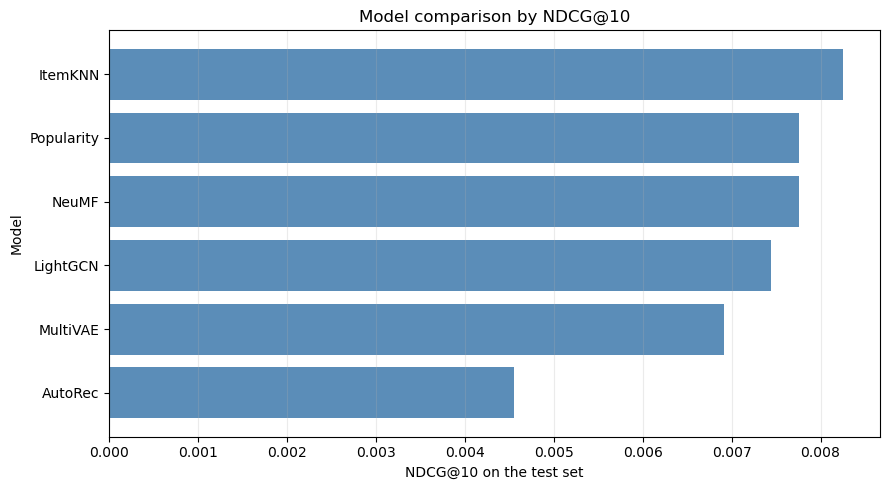

Najbolji model prema NDCG@10: ItemKNN (0.008256)
Najbolji neuronski model: NeuMF (0.007754)


In [17]:
plot_data = metric_results.sort_values("NDCG@10")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["model"], plot_data["NDCG@10"], color="#5B8DB8")
plt.xlabel("NDCG@10 on the test set")
plt.ylabel("Model")
plt.title("Model comparison by NDCG@10")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

best_model = metric_results.iloc[0]
best_neural = metric_results[metric_results["model"].isin(
    ["AutoRec", "MultiVAE", "NeuMF", "LightGCN"]
)].iloc[0]
print(f"Najbolji model prema NDCG@10: {best_model['model']} ({best_model['NDCG@10']:.6f})")
print(f"Najbolji neuronski model: {best_neural['model']} ({best_neural['NDCG@10']:.6f})")


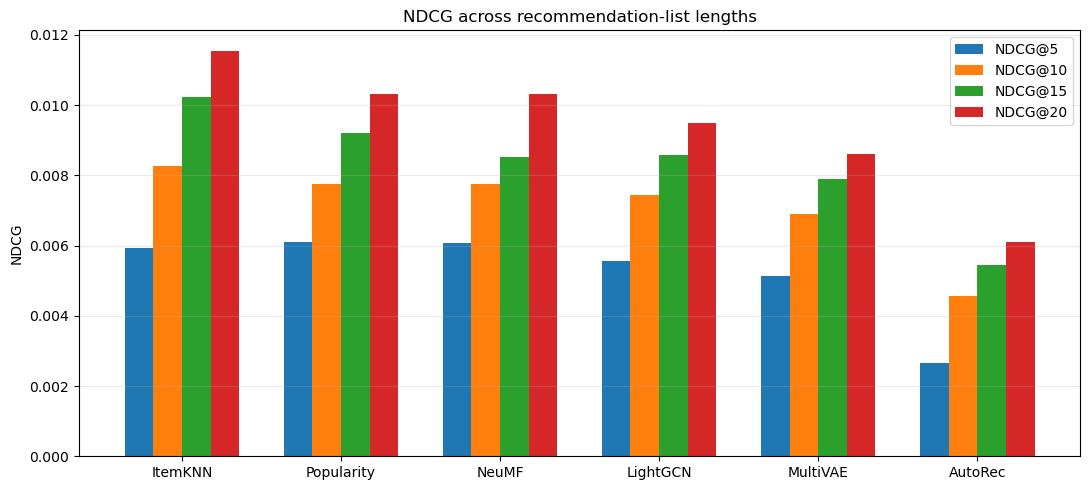

In [18]:
ndcg_columns = ["NDCG@5", "NDCG@10", "NDCG@15", "NDCG@20"]
x = np.arange(len(metric_results))
width = 0.18

plt.figure(figsize=(11, 5))
for offset, column in enumerate(ndcg_columns):
    plt.bar(x + (offset - 1.5) * width, metric_results[column], width, label=column)
plt.xticks(x, metric_results["model"])
plt.ylabel("NDCG")
plt.title("NDCG across recommendation-list lengths")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 3. Neural Model Validation Curves

The plots show validation NDCG@10 across training epochs for the selected configuration of each neural model.

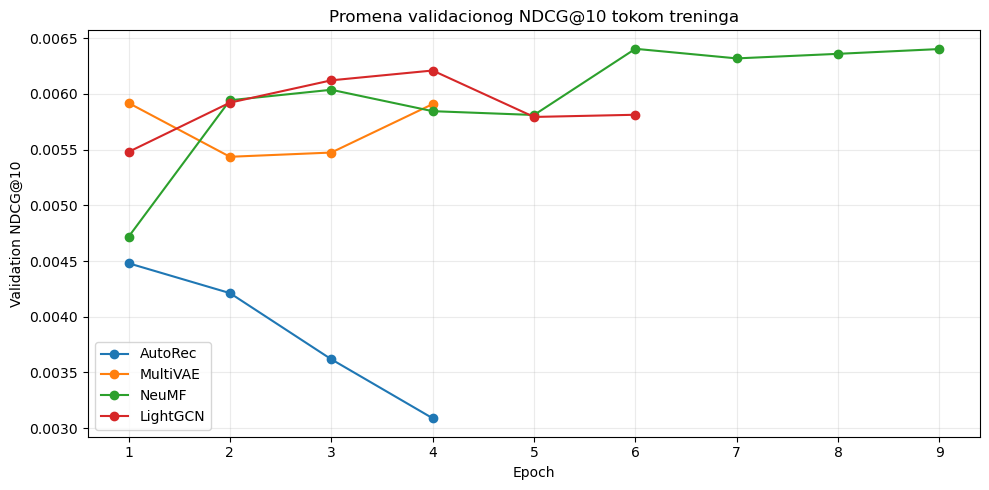

In [19]:
history_paths = {
    "AutoRec": autoencoder_dir / f"ar_history_{run_name}_seed_{seed}.csv",
    "MultiVAE": autoencoder_dir / f"multivae_history_{run_name}_seed_{seed}.csv",
    "NeuMF": neumf_dir / f"neumf_history_{run_name}_seed_{seed}.csv",
    "LightGCN": lightgcn_dir / f"lightgcn_history_{run_name}_seed_{seed}.csv",
}

history_parts = []
for model, path in history_paths.items():
    data = pd.read_csv(path)
    data["model"] = model
    history_parts.append(data)
history = pd.concat(history_parts, ignore_index=True)

plt.figure(figsize=(10, 5))
for model, data in history.groupby("model", sort=False):
    plt.plot(data["epoch"], data["validation_ndcg_10"], marker="o", label=model)
plt.xlabel("Epoch")
plt.ylabel("Validation NDCG@10")
plt.title("Promena validacionog NDCG@10 tokom treninga")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 4. Performance by User History Length

Users are divided into four groups according to the number of interactions preceding their test target. Hit@10 and NDCG@10 are computed for each group and model to examine how relative performance varies with shorter or longer user histories.


In [20]:
history_rows = []
for model in model_names:
    rank_column = f"{model_slugs[model]}_rank_at_20"
    for group, data in per_user.groupby("history_group", observed=False):
        ranks = data[rank_column].to_numpy()
        hits = (ranks > 0) & (ranks <= 10)
        discounted = np.zeros(len(ranks), dtype=np.float64)
        discounted[hits] = 1 / np.log2(ranks[hits] + 1)
        history_rows.append({
            "model": model,
            "history_group": str(group),
            "users": len(data),
            "Hit@10": hits.mean(),
            "NDCG@10": discounted.mean(),
        })

history_results = pd.DataFrame(history_rows)
history_results.to_csv(
    analysis_dir / f"history_results_{run_name}_seed_{seed}.csv", index=False
)
history_results.pivot(index="history_group", columns="model", values="NDCG@10").round(6)


model,AutoRec,ItemKNN,LightGCN,MultiVAE,NeuMF,Popularity
history_group,,,,,,
16–30,0.005455,0.010201,0.008999,0.008367,0.009204,0.009222
31+,0.009204,0.011894,0.010303,0.008772,0.010557,0.010575
3–8,0.002963,0.006770,0.006246,0.006107,0.006616,0.006618
9–15,0.003435,0.007997,0.007459,0.006695,0.007543,0.007564


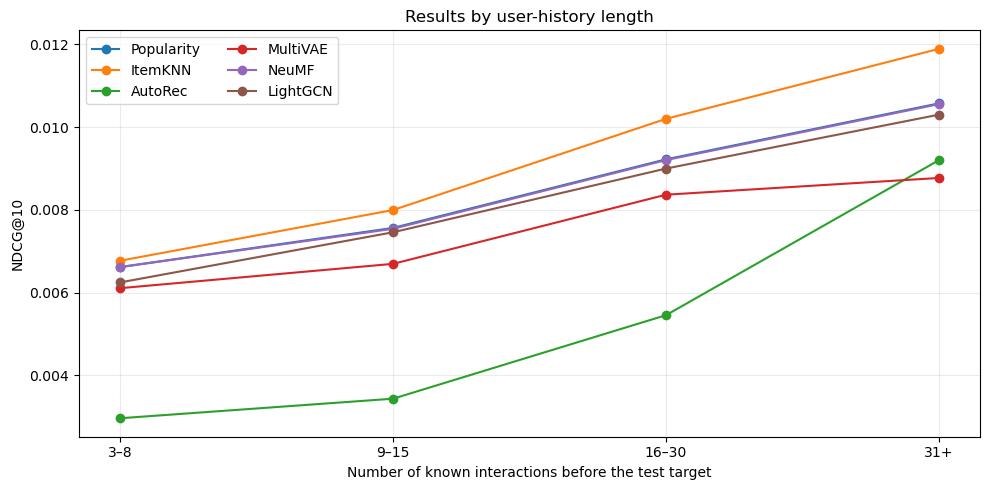

In [21]:
history_order = ["3–8", "9–15", "16–30", "31+"]
plt.figure(figsize=(10, 5))
for model in model_names:
    data = history_results[history_results["model"] == model].set_index("history_group").reindex(history_order)
    plt.plot(history_order, data["NDCG@10"], marker="o", label=model)
plt.xlabel("Number of known interactions before the test target")
plt.ylabel("NDCG@10")
plt.title("Results by user-history length")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Performance by Target-App Popularity and Category

Apps are divided by training interaction count into the most popular 10%, the next 40%, and the least popular 50%. These groups are based on app rank by training frequency, not equal numbers of test interactions. Category-level results are also reported for categories with at least 300 test targets.


In [22]:
popularity_rows = []
for model in model_names:
    rank_column = f"{model_slugs[model]}_rank_at_20"
    for group, data in per_user.groupby("target_popularity_group", observed=False):
        ranks = data[rank_column].to_numpy()
        hits = (ranks > 0) & (ranks <= 10)
        discounted = np.zeros(len(ranks), dtype=np.float64)
        discounted[hits] = 1 / np.log2(ranks[hits] + 1)
        popularity_rows.append({
            "model": model,
            "target_popularity_group": str(group),
            "test_targets": len(data),
            "Hit@10": hits.mean(),
            "NDCG@10": discounted.mean(),
        })

target_popularity_results = pd.DataFrame(popularity_rows)
target_popularity_results.to_csv(
    analysis_dir / f"target_popularity_results_{run_name}_seed_{seed}.csv", index=False
)
target_popularity_results.pivot(
    index="target_popularity_group", columns="model", values="NDCG@10"
).round(6)


model,AutoRec,ItemKNN,LightGCN,MultiVAE,NeuMF,Popularity
target_popularity_group,,,,,,
Bottom 50% least popular,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Next 40%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Top 10% most popular,0.010997,0.019937,0.017982,0.016691,0.018723,0.018743


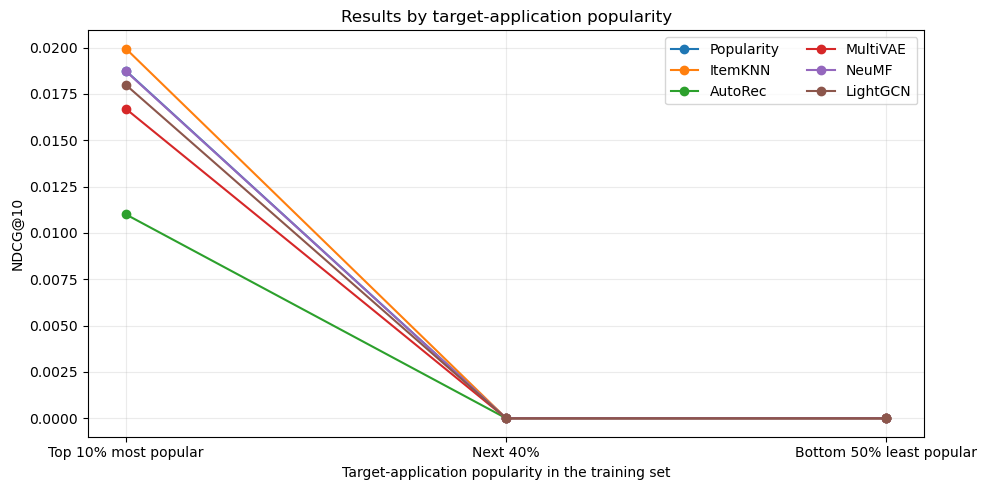

In [23]:
popularity_order = ["Top 10% most popular", "Next 40%", "Bottom 50% least popular"]
plt.figure(figsize=(10, 5))
for model in model_names:
    data = target_popularity_results[
        target_popularity_results["model"] == model
    ].set_index("target_popularity_group").reindex(popularity_order)
    plt.plot(popularity_order, data["NDCG@10"], marker="o", label=model)
plt.xlabel("Target-application popularity in the training set")
plt.ylabel("NDCG@10")
plt.title("Results by target-application popularity")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [24]:
category_sizes = per_user["app_category"].value_counts(dropna=False)
eligible_categories = category_sizes[category_sizes >= 300].index
category_rows = []

for model in model_names:
    rank_column = f"{model_slugs[model]}_rank_at_20"
    subset = per_user[per_user["app_category"].isin(eligible_categories)].copy()
    for category, data in subset.groupby("app_category", dropna=False):
        ranks = data[rank_column].to_numpy()
        hits = (ranks > 0) & (ranks <= 10)
        discounted = np.zeros(len(ranks), dtype=np.float64)
        discounted[hits] = 1 / np.log2(ranks[hits] + 1)
        category_rows.append({
            "model": model,
            "app_category": category,
            "test_targets": len(data),
            "Hit@10": hits.mean(),
            "NDCG@10": discounted.mean(),
        })

category_results = pd.DataFrame(category_rows)
category_results.to_csv(
    analysis_dir / f"category_results_{run_name}_seed_{seed}.csv", index=False
)

top_categories = category_sizes.head(15).index
category_pivot = (
    category_results[category_results["app_category"].isin(top_categories)]
    .pivot(index="app_category", columns="model", values="NDCG@10")
    .reindex(top_categories)
    .reindex(columns=model_names)
)
category_pivot.round(6)


model,Popularity,ItemKNN,AutoRec,MultiVAE,NeuMF,LightGCN
app_category,,,,,,
Action,0.000000,0.001882,0.000303,0.003719,0.000000,0.000000
Casual,0.020298,0.018935,0.026921,0.024027,0.019942,0.027320
Puzzle,0.000000,0.000043,0.005846,0.002806,0.000000,0.000000
Simulation,0.000000,0.000009,0.000000,0.000000,0.000000,0.000000
Finance,0.008212,0.007453,0.001684,0.008945,0.008213,0.006922
Role Playing,0.000000,0.000000,0.000000,0.000000,0.000000,0.000010
Communication,0.061067,0.056359,0.023326,0.040248,0.061019,0.058242
Strategy,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Tools,0.000000,0.000039,0.000037,0.000000,0.000000,0.000000


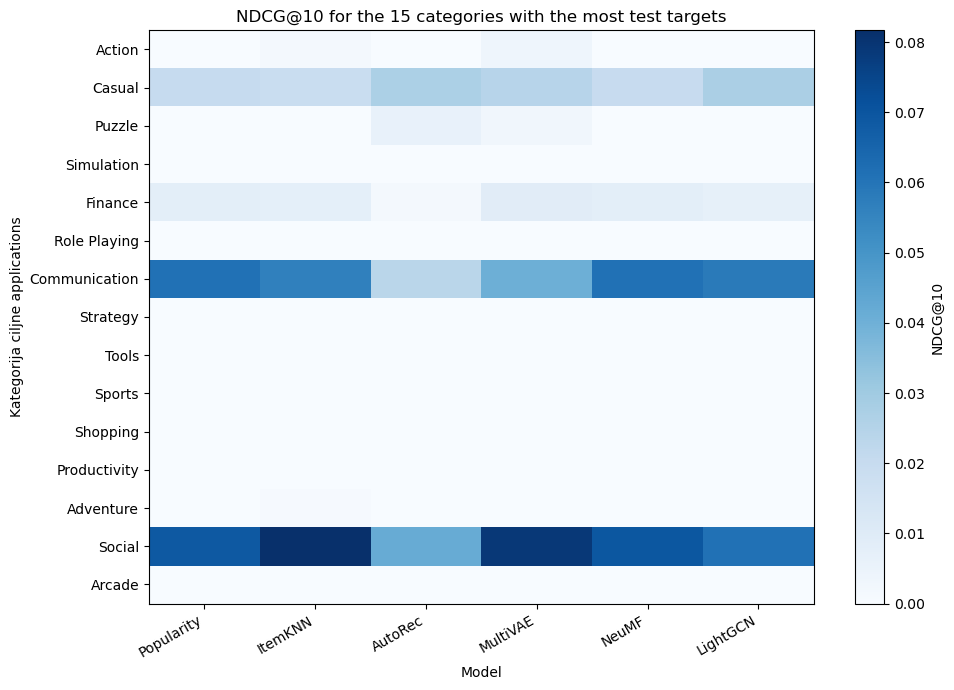

In [25]:
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(category_pivot.to_numpy(), aspect="auto", cmap="Blues")
ax.set_xticks(np.arange(len(category_pivot.columns)), category_pivot.columns, rotation=30, ha="right")
ax.set_yticks(np.arange(len(category_pivot.index)), category_pivot.index)
ax.set_xlabel("Model")
ax.set_ylabel("Kategorija ciljne applications")
ax.set_title("NDCG@10 for the 15 categories with the most test targets")
fig.colorbar(image, ax=ax, label="NDCG@10")
plt.tight_layout()
plt.show()


## 6. Catalog Coverage and Recommendation Popularity

Catalog coverage is the fraction of candidate apps appearing in at least one Top-10 recommendation list. The analysis also measures the share of all recommendations assigned to the ten most popular training apps and the share assigned to the less popular half of the catalog. These measures reveal whether a model recommends a broad range of apps across users or concentrates on the most popular items.


In [26]:
top_10_items = set(app_counts.head(10)["item_idx"].astype(int))
tail_items = set(
    popularity_rank.loc[
        popularity_rank["popularity_fraction"] >= 0.50, "item_idx"
    ].astype(int)
)
item_popularity = app_counts.set_index("item_idx")["interaction_count"].reindex(
    np.arange(num_items)
).to_numpy()

def weighted_median(values, weights):
    order = np.argsort(values)
    sorted_values = values[order]
    sorted_weights = weights[order]
    cutoff = sorted_weights.sum() / 2
    return sorted_values[np.searchsorted(np.cumsum(sorted_weights), cutoff)]

catalog_rows = []
for model in model_names:
    data = catalog_counts[catalog_counts["model"] == model].sort_values("item_idx")
    counts_10 = data["recommendation_count_at_10"].to_numpy(dtype=np.int64)
    counts_20 = data["recommendation_count_at_20"].to_numpy(dtype=np.int64)
    total_10 = counts_10.sum()
    catalog_rows.append({
        "model": model,
        "unique_apps_at_10": int((counts_10 > 0).sum()),
        "catalog_coverage_at_10_percent": (counts_10 > 0).mean() * 100,
        "unique_apps_at_20": int((counts_20 > 0).sum()),
        "catalog_coverage_at_20_percent": (counts_20 > 0).mean() * 100,
        "top_10_popular_share_percent": counts_10[list(top_10_items)].sum() / total_10 * 100,
        "tail_share_percent": counts_10[list(tail_items)].sum() / total_10 * 100,
        "median_train_interactions_of_recommended_apps": weighted_median(
            item_popularity, counts_10
        ),
    })

catalog_results = pd.DataFrame(catalog_rows).sort_values(
    "catalog_coverage_at_10_percent", ascending=False
)
catalog_results.to_csv(
    analysis_dir / f"catalog_results_{run_name}_seed_{seed}.csv", index=False
)
catalog_results.round(4)


,model,unique_apps_at_10,catalog_coverage_at_10_percent,unique_apps_at_20,catalog_coverage_at_20_percent,top_10_popular_share_percent,tail_share_percent,median_train_interactions_of_recommended_apps
5,LightGCN,4433,43.5804,6036,59.3394,90.0675,1.3338,9173
1,ItemKNN,1043,10.2536,1644,16.1620,79.9509,0.0015,9173
2,AutoRec,120,1.1797,335,3.2934,58.1264,0.0000,8579
3,MultiVAE,12,0.1180,35,0.3441,81.4176,0.0000,9173
4,NeuMF,12,0.1180,23,0.2261,99.7884,0.0000,9173
0,Popularity,10,0.0983,20,0.1966,100.0000,0.0000,9173


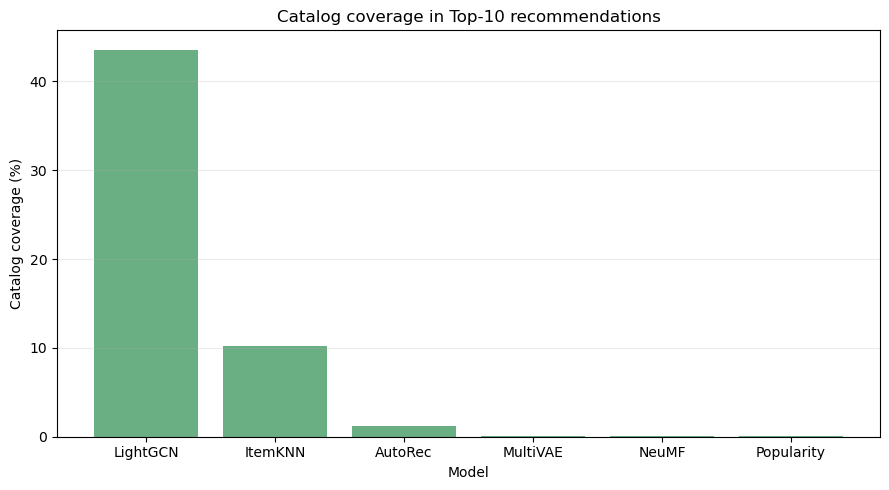

In [27]:
plt.figure(figsize=(9, 5))
plt.bar(
    catalog_results["model"],
    catalog_results["catalog_coverage_at_10_percent"],
    color="#6AAE84"
)
plt.xlabel("Model")
plt.ylabel("Catalog coverage (%)")
plt.title("Catalog coverage in Top-10 recommendations")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Evaluation Summary and Limitations

The final comparison considers ranking performance alongside model behavior across user history lengths and different parts of the catalog.

Each neural configuration is trained once with `seed = 42`, so this analysis does not measure variation across multiple independent training runs.

In [28]:
final_overview = metric_results[["model", "Hit@10", "NDCG@10"]].merge(
    catalog_results[[
        "model", "catalog_coverage_at_10_percent",
        "top_10_popular_share_percent", "tail_share_percent"
    ]],
    on="model", how="left"
)
final_overview.to_csv(
    analysis_dir / f"final_overview_{run_name}_seed_{seed}.csv", index=False
)
final_overview.round(6)


,model,Hit@10,NDCG@10,catalog_coverage_at_10_percent,top_10_popular_share_percent,tail_share_percent
0,ItemKNN,0.016872,0.008256,10.253637,79.950935,0.001457
1,Popularity,0.015051,0.007762,0.098309,100.000000,0.000000
2,NeuMF,0.015044,0.007754,0.117971,99.788443,0.000000
3,LightGCN,0.014648,0.007447,43.580417,90.067505,1.333831
4,MultiVAE,0.013860,0.006912,0.117971,81.417591,0.000000
5,AutoRec,0.010557,0.004554,1.179709,58.126386,0.000000
